# Combo 2 — A wall's boundary element *is* a Column (§18.10.6)

The cleanest reuse in the toolkit: a wall's **boundary element (BE)** is a real `Column` object. The wall owns the web; it hands the BE detailing (Ash, hoops, `hx`, `Mpr`) to the column engine, and maps its own demands onto the column with `wall_demands_to_be`:

```
Pu -> Pu      Mu(in-plane) -> Mux     Mu(out) -> Muy
Vu(in-plane) -> Vuy     Vu(out) -> Vux
```

This notebook triggers a BE, pulls it out as a `Column`, and designs it as one.

## Setup — a wall that needs boundary elements

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.simplefilter("ignore", DeprecationWarning)
_root = pathlib.Path.cwd().resolve()
while _root != _root.parent and not (_root / "design" / "__init__.py").is_file():
    _root = _root.parent
if (_root / "design").is_dir() and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import matplotlib.pyplot as plt
from design.common.materials import Concrete, Steel
from design.walls.wall import Wall
from design.walls.boundary import (
    boundary_element_required_displacement, boundary_element_required_stress,
    c_at_demand)
from design.common.contracts import wall_demands_to_be

concrete = Concrete(fc=35.0)
steel = Steel(fy=420.0)

wall = Wall.rectangular(
    lw=4000, tw=300, hw=18000, lu=3000, concrete=concrete, steel=steel,
    n_y_web=10, db_web=12, cover=25,
    be_top_length=600, be_bot_length=600,
    n_x_be=3, n_y_be=4, db_be=25, db_stirrup=10,
    seismic=True, rho_t=0.0025, rho_l=0.0025, label='W-BE').run()
demands = wall.demands(Pu=3000, Mu=20000, Mu_out=400, Vu=2500,
                       Vu_out=150, delta_u=90, sigma_max=10.0)
print('has boundary elements =', wall.has_boundary_elements)

has boundary elements = True


## The §18.10.6 triggers, raw

The two BE checks are pure functions you can call directly. The displacement check needs the neutral-axis depth `c` the wall develops under the demand (via `c_at_demand`); the stress check needs the extreme compressive fibre stress.

In [2]:
cap = wall.capacity()
c = c_at_demand(cap.diagram, Pu=demands.Pu, Mu=demands.Mu)
lw = wall.section.lw
be_disp = boundary_element_required_displacement(
    c=c, lw=lw, delta_u=demands.delta_u, hw=wall.hw)
be_stress = boundary_element_required_stress(
    sigma_max_compressive=demands.sigma_max, fc=concrete.fc)
print(f"c at demand   = {c:.0f} mm   (lw = {lw:.0f} mm)")
print(f"BE by drift   = {be_disp}   (delta_u/hw = {demands.delta_u/wall.hw:.4f})")
print(f"BE by stress  = {be_stress}  (sigma_max = {demands.sigma_max} MPa, "
      f"0.2 f'c = {0.2*concrete.fc:.1f} MPa)")

c at demand   = 368 mm   (lw = 4000 mm)
BE by drift   = False   (delta_u/hw = 0.0050)
BE by stress  = True  (sigma_max = 10.0 MPa, 0.2 f'c = 7.0 MPa)


## The BE *is* a Column — inspect it

`wall.be_top` is a fully-fledged `Column`. We can query its capacity exactly like any other column.

In [3]:
be = wall.be_top
print("type(wall.be_top) =", type(be).__name__)
be.run()
print(f"BE  Po = {be.Po:.0f} kN   To = {be.To:.0f} kN   "
      f"phi_Vn_x = {be.phi_Vn_x:.0f} kN")

type(wall.be_top) = Column
BE  Po = 7271 kN   To = -2062 kN   phi_Vn_x = 122 kN


## Map wall demands onto the BE column and check it

`wall_demands_to_be` is the canonical translation. The BE then checks itself with the column contract.

In [4]:
be_demands = wall_demands_to_be(demands)
print("mapped ColumnDemands:", be_demands)
be_chk = be.check(be_demands)
print(f"BE PMM ratio = {be_chk.ratio_pmm:.2f}   shear ratio = {be_chk.ratio_shear:.2f}   "
      f"passed = {be_chk.passed}")

mapped ColumnDemands: ColumnDemands(Pu=3.0, Mux=0.02, Muy=0.0004, Vux=0.15, Vuy=2.5)
BE PMM ratio = 0.00   shear ratio = 4.33   passed = False


## Drift sweep — when does the BE switch on?

Holding everything else fixed, we sweep the inelastic top drift `delta_u` and watch the displacement-based trigger flip. This is the §18.10.6.2 threshold made visible.

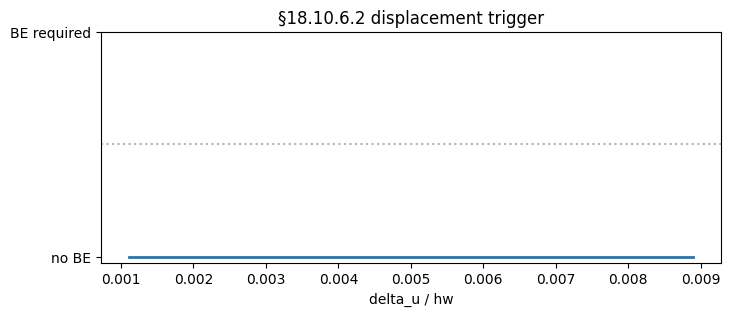

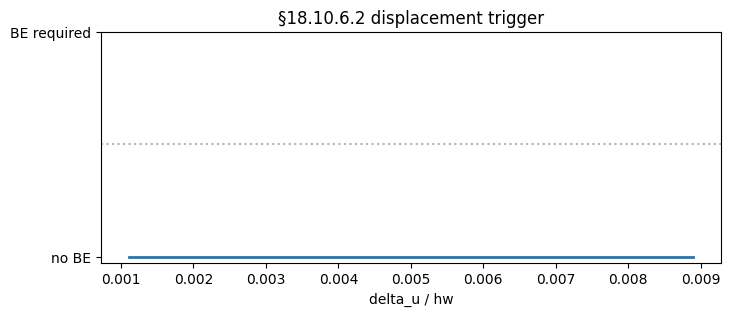

In [5]:
deltas = np.linspace(20, 160, 40)
flags = [boundary_element_required_displacement(c=c, lw=lw, delta_u=d, hw=wall.hw)
         for d in deltas]
fig, ax = plt.subplots(figsize=(8, 3))
ax.step(deltas / wall.hw, [1 if f else 0 for f in flags], where="post", lw=2)
ax.axhline(0.5, color="0.7", ls=":")
ax.set_yticks([0, 1]); ax.set_yticklabels(["no BE", "BE required"])
ax.set_xlabel("delta_u / hw"); ax.set_title("§18.10.6.2 displacement trigger")
fig

---
**Takeaway.** A wall is a *composition*: a web it owns plus boundary elements that are full `Column` objects. One element type powers two members, and `wall_demands_to_be` is the only glue you ever need.